# 02 · k-nearest neighbours, from scratch

**Read first:** `01_theory/04_knn.md`

You will build k-NN piece by piece:

1. the Minkowski distance, and why we can skip the root
2. finding the k nearest wines
3. the weighted vote, the imbalance correction α, and the tie rule
4. checking the result against scikit-learn — **identical answers**
5. the effect of k, and the two baselines

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data")

def load(path, is_red):
    raw = np.genfromtxt(path, delimiter=";", skip_header=1)
    return np.column_stack([raw[:, :11], np.full(len(raw), float(is_red))]), raw[:, 11].astype(int)

def drop_exact_duplicates(X, s):
    _, first = np.unique(np.column_stack([X, s]), axis=0, return_index=True)
    keep = np.sort(first)
    return X[keep], s[keep]

Xr, sr = load(DATA / "winequality-red.csv", 1)
Xw, sw = load(DATA / "winequality-white.csv", 0)
X, s = drop_exact_duplicates(np.vstack([Xr, Xw]), np.concatenate([sr, sw]))
y = np.where(s <= 5, 0, np.where(s == 6, 1, 2))
GRADES = ["low", "medium", "high"]

# a stratified 80/20 split (notebook 04 explains stratification)
rng = np.random.default_rng(42)
test_mask = np.zeros(len(y), bool)
for c in range(3):
    rows = rng.permutation(np.flatnonzero(y == c))
    test_mask[rows[: len(rows) // 5]] = True
Xtr, ytr, Xte, yte = X[~test_mask], y[~test_mask], X[test_mask], y[test_mask]

# z-score, fitted on the TRAINING rows only (notebook 01)
mean, std = Xtr.mean(0), Xtr.std(0)
std[std == 0] = 1
Xtr, Xte = (Xtr - mean) / std, (Xte - mean) / std
print("train", Xtr.shape, " test", Xte.shape)

train (4258, 12)  test (1062, 12)


## 1. The distance

$$ d(a,b) = \Big(\sum_i w_i\,|a_i-b_i|^p\Big)^{1/p} $$

p = 1 is Manhattan, p = 2 is Euclidean. All weights $w_i$ are 1 for now (notebook 05 learns them).

The **root does not change the order**: if 25 < 36 then 5 < 6. To *rank* wines we can use the sum
without the root — the "power distance" — and take the root only for the k wines that vote.

In [2]:
def power_distance(Xtrain, q, p=2, w=None):
    """Sum of w * |difference|^p from q to every training row. No root."""
    w = np.ones(Xtrain.shape[1]) if w is None else w
    return (w * np.abs(Xtrain - q) ** p).sum(axis=1)

def minkowski(a, b, p=2, w=None):
    return power_distance(a[None, :], b, p, w)[0] ** (1 / p)

print(minkowski(np.array([0., 0.]), np.array([3., 4.]), p=2))   # 5, Pythagoras
print(minkowski(np.array([0., 0.]), np.array([3., 4.]), p=1))   # 7, Manhattan

d_pow = power_distance(Xtr, Xte[0])
print("same order with and without the root:",
      np.array_equal(np.argsort(d_pow, kind="stable"), np.argsort(d_pow ** 0.5, kind="stable")))

5.0
7.0
same order with and without the root: True


## 2. The k nearest

Sort the distances and take the first k. `kind="stable"` means that two wines at exactly the same
distance stay in row order — so the answer is the same every time.

In [3]:
def k_nearest(Xtrain, q, k, p=2, w=None):
    d = power_distance(Xtrain, q, p, w)
    idx = np.argsort(d, kind="stable")[:k]
    return idx, d[idx] ** (1 / p)            # rows, and REAL distances

idx, dist = k_nearest(Xtr, Xte[0], k=5)
print("true grade of the query:", GRADES[yte[0]])
for i, d in zip(idx, dist):
    print(f"  row {i:5d}  distance {d:.3f}  grade {GRADES[ytr[i]]}")

true grade of the query: low
  row   180  distance 0.829  grade medium
  row    55  distance 0.864  grade medium
  row   125  distance 0.918  grade low
  row   179  distance 1.048  grade low
  row   270  distance 1.075  grade medium


## 3. The vote

Each neighbour votes for its grade with strength

$$ \text{vote} = \frac{1}{d + \varepsilon} \Big/ \text{prior}[\text{grade}]^{\alpha} $$

* closer neighbours vote louder
* α = 0 → no correction; α = 1 → a rare "high" vote is boosted to cancel its rarity
* **ties** → the grade of the nearest neighbour among the tied grades wins
* **confidence** = the winner's share of all votes

In [4]:
EPS = 1e-9
priors = np.bincount(ytr, minlength=3) / len(ytr)
print("priors:", np.round(priors, 3))

def vote(neigh_grades, neigh_dist, priors, alpha=0.0, n_classes=3):
    w = 1.0 / (neigh_dist + EPS) / priors[neigh_grades] ** alpha
    scores = np.zeros(n_classes)
    np.add.at(scores, neigh_grades, w)            # scores[g] += w for every neighbour
    best = np.flatnonzero(np.isclose(scores, scores.max()))
    if len(best) == 1:
        winner = best[0]
    else:                                         # tie: nearest neighbour among the tied grades
        winner = next(g for g in neigh_grades if g in best)
    return winner, scores[winner] / scores.sum()

# the worked example from the theory chapter
winner, conf = vote(np.array([2, 1, 1]), np.array([0.1, 0.9, 1.0]), priors)
print(f"winner: {GRADES[winner]}, confidence {conf:.2f}")   # theory 4.4: high, 0.83
g = np.array([1, 1, 2]); d = np.ones(3); pr = np.array([0.37, 0.44, 0.19])
print("alpha=0 ->", GRADES[vote(g, d, pr, 0)[0]], "   alpha=1 ->", GRADES[vote(g, d, pr, 1)[0]])

priors: [0.374 0.437 0.19 ]
winner: high, confidence 0.83
alpha=0 -> medium    alpha=1 -> high


## 4. Putting it together

In [5]:
class KNN:
    def __init__(self, k=15, p=2, alpha=0.0, w=None):
        self.k, self.p, self.alpha, self.w = k, p, alpha, w

    def fit(self, X, y):
        self.X, self.y = X, y                     # k-NN "training" = remembering
        self.priors = np.bincount(y, minlength=3) / len(y)
        return self

    def predict_one(self, q):
        idx, dist = k_nearest(self.X, q, self.k, self.p, self.w)
        return vote(self.y[idx], dist, self.priors, self.alpha)

    def predict(self, Q):
        return np.array([self.predict_one(q)[0] for q in Q])

pred = KNN(k=15).fit(Xtr, ytr).predict(Xte)
print("accuracy:", np.mean(pred == yte).round(3))

accuracy: 0.599


## 5. Is it right? Compare with scikit-learn

`KNeighborsClassifier(weights="distance")` does the same vote with α = 0. We demand **identical**
answers, not "similar accuracy". (sklearn is used *only* for this check.)

In [6]:
from sklearn.neighbors import KNeighborsClassifier

for p in (1, 2):
    ours = KNN(k=15, p=p).fit(Xtr, ytr).predict(Xte)
    ref = KNeighborsClassifier(n_neighbors=15, p=p, weights="distance", algorithm="brute").fit(Xtr, ytr).predict(Xte)
    print(f"p={p}: {np.sum(ours != ref)} different answers out of {len(ref)}")

p=1: 0 different answers out of 1062


p=2: 0 different answers out of 1062


## 6. Macro-F1 and the effect of α

In [7]:
def macro_f1(y_true, y_pred, n=3):
    f1s = []
    for c in range(n):
        tp = np.sum((y_pred == c) & (y_true == c))
        prec = tp / max(np.sum(y_pred == c), 1)
        rec = tp / max(np.sum(y_true == c), 1)
        f1s.append(0 if prec + rec == 0 else 2 * prec * rec / (prec + rec))
    return np.mean(f1s)

def recall_of(c, y_true, y_pred):
    return np.mean(y_pred[y_true == c] == c)

for alpha in (0, 0.5, 1):
    pr = KNN(k=15, alpha=alpha).fit(Xtr, ytr).predict(Xte)
    print(f"alpha={alpha:<3}  macro-F1 {macro_f1(yte, pr):.3f}   recall(high) {recall_of(2, yte, pr):.3f}")

alpha=0    macro-F1 0.582   recall(high) 0.443


alpha=0.5  macro-F1 0.580   recall(high) 0.557


alpha=1    macro-F1 0.565   recall(high) 0.701


Higher α finds more high-quality wines, at a small price elsewhere. The project's tuning rule picks
among configurations that are equally good overall the one that finds the most high wines.

## 7. The effect of k

Computing the neighbours once for the largest k and reusing them for every smaller k is a big
saving (theory 6.2): the neighbours do not depend on k.

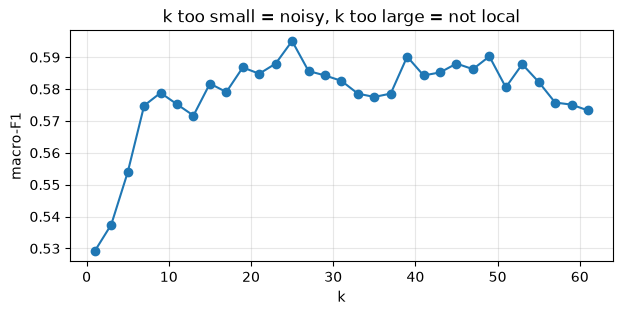

In [8]:
K_MAX = 61
P = np.stack([power_distance(Xtr, q) for q in Xte])          # all test x train distances
order = np.argsort(P, axis=1, kind="stable")[:, :K_MAX]
dists = np.take_along_axis(P, order, 1) ** 0.5

ks = list(range(1, K_MAX + 1, 2))
scores = []
for k in ks:
    pr = np.array([vote(ytr[order[i, :k]], dists[i, :k], priors)[0] for i in range(len(Xte))])
    scores.append(macro_f1(yte, pr))

plt.figure(figsize=(7, 3))
plt.plot(ks, scores, marker="o")
plt.xlabel("k"); plt.ylabel("macro-F1"); plt.grid(alpha=.3)
plt.title("k too small = noisy, k too large = not local")
plt.show()

## 8. The baselines

Always compare with something simple. If k-NN cannot beat these, it has learned nothing.

In [9]:
majority = np.full_like(yte, np.bincount(ytr).argmax())
centroids = np.stack([Xtr[ytr == c].mean(0) for c in range(3)])
centroid_pred = np.argmin(((Xte[:, None, :] - centroids[None]) ** 2).sum(2), axis=1)
unscaled = KNN(k=15).fit(X[~test_mask], ytr).predict(X[test_mask])

print(f"majority      {macro_f1(yte, majority):.3f}")
print(f"centroid      {macro_f1(yte, centroid_pred):.3f}")
print(f"k-NN unscaled {macro_f1(yte, unscaled):.3f}")
print(f"k-NN scaled   {macro_f1(yte, KNN(k=15).fit(Xtr, ytr).predict(Xte)):.3f}")

majority      0.203
centroid      0.484
k-NN unscaled 0.459


k-NN scaled   0.582


**Careful:** these numbers come from *one* split. Notebook 04 shows why one split is not enough and
how the project measures honestly.

## ✍️ Try it yourself

1. Explain one prediction: print the 5 neighbours of `Xte[10]`, their grades and votes. Would a wine
   maker be convinced?
2. Make the vote **unweighted** (every vote = 1). How often do ties happen now with k = 4?
3. Find a k where p = 1 beats p = 2. Is the difference larger than the noise of a single split?

Then solve exercises 5–8 in `03_exercises/`.